# Stage 1b Model Comparison — Reading Drawings and Photographs (VLM)

This notebook is one of a set of eight, each testing/comparing candidate models
for one stage of the starwheel CAD-generation pipeline described in
`model_types_by_stage.md`. It tests **Stage 1b only**:

> *"Model type: vision-language model (VLM). Candidates: Qwen3.6-VL, Gemma 4
> multimodal. ... Only add this if you accept images -- it roughly doubles
> serving cost. Input: a photo of a bottle or a scanned PDF drawing, plus the
> same instruction. Output: the same JSON as above, with fields filled from
> what is legible in the image and left null where the image is unclear."*

Stage 1b sits next to Stage 1 (text-only spec extraction): same output schema,
same "leave it null rather than guess" discipline, but the input is now an
**image** the model has to actually read, not just text it has to parse.

**No real bottle-drawing dataset is available here.** Supplier drawings are
either proprietary or simply don't exist as a public benchmark set for this
niche (custom capping-machine starwheels), so this notebook builds its own
test case: a synthetic, labeled technical-sketch-style image of a bottle,
drawn in Python with Pillow, in Section 1 below. This keeps the notebook
fully reproducible with no external file dependency, and -- more importantly
-- it lets us **control the ground truth exactly**, including deliberately
leaving some fields (`ovality_mm`, `shape`) unlabeled in the drawing. That is
the whole point of the check in Section 5: a model that invents a plausible
value for something that was never actually shown in the image is the
Stage-1b analogue of Stage 4's "plausible but wrong" CAD script, and gets
treated as an automatic reject.

**This sandbox has no outbound network access** to model-hosting APIs
(OpenRouter, Hugging Face, etc. all time out from here). So this notebook is
pre-executed in this sandbox using only the **local/offline baseline
adapters** in Section 3, which proves the harness itself -- the synthetic
image, the prompt, and the four-check validator -- is correct. The **real**
VLM candidates in Section 4 (OpenRouter, multimodal chat completions) need to
be run by you, elsewhere, with your own `OPENROUTER_API_KEY` -- see Section 9.
When run here, those two adapters show up honestly as `generation_failed`
trials rather than being silently skipped or faked.

## 0. Setup

Installs anything missing. `pillow` builds the synthetic bottle sketch in
Section 1; `pandas`/`matplotlib` are for the Section 7 comparison table and
chart. No GPU and no heavy ML library is needed for this stage's local
adapters -- they're deterministic Python, not local model inference.

In [1]:
import sys
import subprocess

def _ensure(*packages):
    # Import-or-install: cheap no-op when already present, but makes the
    # notebook self-contained on a bare kernel too.
    for pkg in packages:
        mod_name = {"pillow": "PIL"}.get(pkg.split("==")[0].lower(), pkg.split("==")[0].replace("-", "_"))
        try:
            __import__(mod_name)
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# pillow     -> builds the synthetic bottle sketch (Section 1)
# pandas     -> comparison table (Section 7)
# matplotlib -> accept-rate chart (Section 7) and displaying the sketch inline
_ensure("pillow", "pandas", "matplotlib")
print("dependencies ready")


dependencies ready


### Credentials

**Don't hardcode API keys directly into a notebook cell** -- a notebook with
a key pasted into `os.environ[...] = "sk-or-..."` carries that key in plain
text in the `.ipynb` file itself (including if you save, git-commit, or send
the file to anyone), and Jupyter/Colab has no way to redact it after the
fact. A sibling notebook in this set leaked a real key exactly this way --
treat any key that was ever pasted into a cell as burned and rotate it. The
cell below uses `getpass` instead: it prompts once per session and the key
never gets written into the notebook or its outputs.

In [2]:
import os
from getpass import getpass

# Prompts only if OPENROUTER_API_KEY isn't already set in the environment --
# safe to re-run this cell, it won't ask twice in the same session. Leave
# blank to skip the two real OpenRouter adapters in Section 4.
if not os.environ.get("OPENROUTER_API_KEY"):
    os.environ["OPENROUTER_API_KEY"] = getpass("OpenRouter API key (leave blank to skip qwen3_vl / gemma4_multimodal): ")


In [3]:
# stdlib
import base64                 # encode the synthetic image for the OpenRouter request
import json                    # (de)serializing the Stage 1b JSON payloads
import os                       # env vars: OPENROUTER_API_KEY
import re                        # regex parsing of the accompanying text prompt
import tempfile                   # scratch dir for the generated sketch + debug artifacts
import time                        # generation timing per trial
import urllib.error                 # (kept for callers that want to catch it explicitly)
import urllib.request                # OpenRouter HTTP calls without adding a requests dependency
from pathlib import Path

# third-party
from PIL import Image, ImageDraw, ImageFont   # build + display the synthetic bottle sketch
import pandas as pd                            # comparison table in Section 7

print("pillow / pandas ready")


pillow / pandas ready


## 1. Build the synthetic test image, and the prompt

There is no real supplier-drawing dataset to pull from, so this cell **draws
one**: a simple labeled technical-sketch of a bottle, in the style of a
supplier spec sheet -- an outline with dimension-line callouts, the way a
scanned PDF drawing or a photo of a spec sheet would show it.

Deliberately, only *some* fields are labeled in the drawing:

| Field | In the drawing? |
|---|---|
| `description` / `material` | Yes -- title text "500 mL PET bottle" |
| `body_diameter_mm` | Yes -- `⌀ 64.0 mm` dimension line across the body |
| `height_mm` | Yes -- `210 mm` dimension line down the left side |
| `neck_finish` | Yes -- `PCO-1881` leader label at the neck |
| `ovality_mm` | **No** -- no tolerance line drawn anywhere |
| `shape` | **No** -- a plain symmetric silhouette, never labeled "round" |

The other schema fields (`machine_id`, `part_family`, `target_speed_cpm`,
`closure`, `filled_weight_g`) come from the **accompanying text instruction**
below, exactly like Stage 1's email -- a real submission is "a photo/drawing
plus the same instruction," not an image alone. `ovality_mm` and `shape` are
absent from *both* the image and the text on purpose: they are this
notebook's stand-in for "the image was unclear," and the correct behaviour,
in image form, is identical to Stage 1's text form -- leave them `null` and
say so in `unresolved_questions`, never guess.

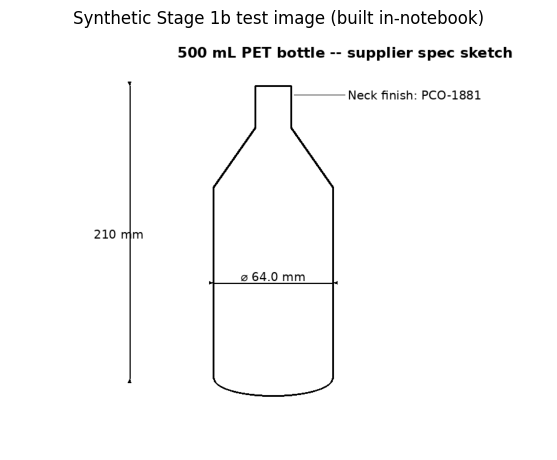

saved to /tmp/stage1b_4zc4xfun/synthetic_bottle_sketch.png


In [4]:
def _arrow_head(draw, tip, direction, size=7, fill="black"):
    '''Small filled triangle so a dimension line reads as an arrow, not just a
    stroke -- direction is a unit-ish (dx, dy) tuple pointing along the line.'''
    dx, dy = direction
    px, py = -dy, dx  # perpendicular
    p1 = tip
    p2 = (tip[0] - dx * size + px * size * 0.4, tip[1] - dy * size + py * size * 0.4)
    p3 = (tip[0] - dx * size - px * size * 0.4, tip[1] - dy * size - py * size * 0.4)
    draw.polygon([p1, p2, p3], fill=fill)


def _dim_line_h(draw, x0, x1, y, label, font):
    draw.line([(x0, y), (x1, y)], fill="black", width=2)
    _arrow_head(draw, (x0, y), (1, 0))
    _arrow_head(draw, (x1, y), (-1, 0))
    w = draw.textlength(label, font=font)
    draw.text(((x0 + x1) / 2 - w / 2, y - 22), label, fill="black", font=font)


def _dim_line_v(draw, y0, y1, x, label, font):
    draw.line([(x, y0), (x, y1)], fill="black", width=2)
    _arrow_head(draw, (x, y0), (0, 1))
    _arrow_head(draw, (x, y1), (0, -1))
    draw.text((x - 60, (y0 + y1) / 2 - 8), label, fill="black", font=font)


def build_synthetic_bottle_sketch(out_path):
    '''Draws a labeled technical-sketch-style bottle image and saves it to
    out_path. This is the ONLY test input every adapter in this notebook is
    given -- built here in code so the notebook has no external file
    dependency and is fully reproducible.'''
    W, H = 900, 700
    img = Image.new("RGB", (W, H), "white")
    draw = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype("DejaVuSans.ttf", 20)
        font_title = ImageFont.truetype("DejaVuSans-Bold.ttf", 24)
    except Exception:
        font = ImageFont.load_default()
        font_title = font

    # Title -- this is where "description" and "material" are legible.
    draw.text((W / 2 - 170, 20), "500 mL PET bottle -- supplier spec sketch", fill="black", font=font_title)

    # Bottle silhouette: neck, shoulder, body, base. Deliberately plain and
    # vertically symmetric -- no cross-section, no "round"/"oval" label
    # anywhere, so `shape` is genuinely not determinable from this drawing.
    body_l, body_r = 340, 540      # body width on the canvas
    body_top, body_bot = 260, 580
    neck_l, neck_r = 410, 470
    neck_top = 90
    shoulder_top = 160

    draw.line([(neck_l, neck_top), (neck_r, neck_top)], fill="black", width=3)          # neck top (finish)
    draw.line([(neck_l, neck_top), (neck_l, shoulder_top)], fill="black", width=3)      # neck side
    draw.line([(neck_r, neck_top), (neck_r, shoulder_top)], fill="black", width=3)
    draw.line([(neck_l, shoulder_top), (body_l, body_top)], fill="black", width=3)      # shoulder taper
    draw.line([(neck_r, shoulder_top), (body_r, body_top)], fill="black", width=3)
    draw.line([(body_l, body_top), (body_l, body_bot)], fill="black", width=3)          # body sides
    draw.line([(body_r, body_top), (body_r, body_bot)], fill="black", width=3)
    draw.arc([body_l, body_bot - 30, body_r, body_bot + 30], 0, 180, fill="black", width=3)  # rounded base

    # Neck finish label -- leader line pointing at the neck.
    draw.line([(neck_r + 5, neck_top + 15), (neck_r + 90, neck_top + 15)], fill="black", width=1)
    draw.text((neck_r + 95, neck_top + 4), "Neck finish: PCO-1881", fill="black", font=font)

    # Diameter dimension line across the body -- body_diameter_mm.
    _dim_line_h(draw, body_l, body_r, 420, "⌀ 64.0 mm", font)

    # Height dimension line down the left side, base to neck top -- height_mm.
    _dim_line_v(draw, neck_top, body_bot, 200, "210 mm", font)

    # NOTE: no ovality tolerance line, no shape label -- left out on purpose.
    img.save(out_path)
    return out_path


_sketch_dir = Path(tempfile.mkdtemp(prefix="stage1b_"))
BOTTLE_IMAGE_PATH = str(_sketch_dir / "synthetic_bottle_sketch.png")
build_synthetic_bottle_sketch(BOTTLE_IMAGE_PATH)

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4.7))
plt.imshow(Image.open(BOTTLE_IMAGE_PATH))
plt.axis("off")
plt.title("Synthetic Stage 1b test image (built in-notebook)")
plt.tight_layout()
plt.show()
print("saved to", BOTTLE_IMAGE_PATH)


In [5]:
# The JSON schema is identical to Stage 1's -- same fields, same "null if not
# determinable" discipline. Only the input channel changes (image + text vs.
# text alone).
STAGE1B_SCHEMA_EXAMPLE = {
    "machine_id": "CAP-16",
    "part_family": "starwheel",
    "target_speed_cpm": 380,
    "container": {
        "description": "500 ml PET still water bottle",
        "body_diameter_mm": 64.0,
        "ovality_mm": None,
        "height_mm": 210,
        "neck_finish": "PCO-1881",
        "closure": "28 mm plastic screw",
        "material": "PET",
        "filled_weight_g": 520,
        "shape": None,
    },
    "unresolved_questions": ["Body ovality tolerance was not supplied. Confirm the maximum ovality."],
    "feasibility_flags": [],
}

# The accompanying TEXT instruction -- everything a supplier email would say
# that a drawing wouldn't (machine, closure, weight, target speed). This is
# what "the same instruction" in the source doc refers to: image + text
# together, exactly like Stage 1's email was text alone.
STAGE1B_TEXT_CONTEXT = '''Hi,

We're bringing a new SKU onto the capper (CAP-16) next month. Closure is a
28 mm plastic screw. Filled weight is around 520 g. We want to run at 380
containers per minute. The container's other dimensions are shown in the
attached drawing -- please read them off that.

Thanks,
Production Planning'''

STAGE1B_PROMPT = f'''You will be given a short text message and an image (a supplier
drawing or photo of a bottle). Extract a JSON object with EXACTLY this shape:

{json.dumps(STAGE1B_SCHEMA_EXAMPLE, indent=2)}

Rules:
- Fill a field from the TEXT if it is stated there.
- Fill a field from the IMAGE if it is legibly drawn/labeled there.
- If a field is not stated in the text AND not legible in the image, set it to
  null. Do NOT guess or infer a plausible-sounding value -- a wrong guess that
  looks right is worse than an honest null.
- List anything you left null (and why) in "unresolved_questions".
- Output ONLY the JSON object, no commentary.

Text message:
-----
{STAGE1B_TEXT_CONTEXT}
-----
'''

print(STAGE1B_PROMPT)


You will be given a short text message and an image (a supplier
drawing or photo of a bottle). Extract a JSON object with EXACTLY this shape:

{
  "machine_id": "CAP-16",
  "part_family": "starwheel",
  "target_speed_cpm": 380,
  "container": {
    "description": "500 ml PET still water bottle",
    "body_diameter_mm": 64.0,
    "ovality_mm": null,
    "height_mm": 210,
    "neck_finish": "PCO-1881",
    "closure": "28 mm plastic screw",
    "material": "PET",
    "filled_weight_g": 520,
    "shape": null
  },
  "unresolved_questions": [
    "Body ovality tolerance was not supplied. Confirm the maximum ovality."
  ],
  "feasibility_flags": []
}

Rules:
- Fill a field from the TEXT if it is stated there.
- Fill a field from the IMAGE if it is legibly drawn/labeled there.
- If a field is not stated in the text AND not legible in the image, set it to
  null. Do NOT guess or infer a plausible-sounding value -- a wrong guess that
  looks right is worse than an honest null.
- List anything y

## 2. Candidate models under test

Researched against the two candidates named in `model_types_by_stage.md`
Stage 1b section (Qwen3.6-VL, Gemma 4 multimodal). Neither exact version
string exists as a real, currently-listed OpenRouter model -- both are
substituted for the closest real, currently-available equivalent, verified
by fetching each model's own OpenRouter page directly (not just a search
snippet) and cross-checking against OpenRouter's vendor listing pages.

| Adapter | Represents | How it runs | Source |
|---|---|---|---|
| `reference_reader` | Correct-by-construction baseline | Local, no model | this notebook (hardcoded ground truth) |
| `regex_ocr_reader` | Stand-in for a competent VLM, different code path | Local, no model | this notebook |
| `hallucinating_reader` | Stand-in for a model that guesses instead of nulling | Local, no model | this notebook |
| `qwen3_vl` | **Real candidate**, substituted for "Qwen3.6-VL" | OpenRouter API, `qwen/qwen3-vl-32b-instruct` -- $0.104/M input, $0.416/M output | [OpenRouter](https://openrouter.ai/qwen/qwen3-vl-32b-instruct) |
| `gemma4_multimodal` | **Real candidate**, matches "Gemma 4 multimodal" | OpenRouter API, `google/gemma-4-31b-it` -- $0.08/M input, $0.35/M output | [OpenRouter](https://openrouter.ai/google/gemma-4-31b-it) |

**Substitution notes:**

- *"Qwen3.6-VL"* does not exist as a listed OpenRouter model. The closest
  real match by naming convention is `qwen/qwen3-vl-32b-instruct` -- part of
  Qwen's current `Qwen3-VL` family (32B/8B/30B-A3B/235B-A22B variants, in
  both `-instruct` and `-thinking` flavours), confirmed live on Qwen's own
  OpenRouter vendor page. A newer, differently-branded dense VL model,
  `qwen/qwen3.8-27b` (released 2026-08-14, per its OpenRouter page), also
  exists and is worth trying as a second data point, but `qwen3-vl-32b-instruct`
  is the closer name-for-name match to the doc's "Qwen3.6-VL" and is what
  this notebook wires up.
- *"Gemma 4 multimodal"* matches real, current OpenRouter listings directly:
  Google's Gemma 4 line (`gemma-4-31b-it`, `gemma-4-26b-a4b-it`, and `:free`
  variants of both) is explicitly multimodal ("text and image input with
  text output" / "text, images, and video"). This notebook uses
  `google/gemma-4-31b-it`, the non-MoE 31B variant, as the closest
  size-comparable pairing to the 32B Qwen candidate above.
- Both slugs were confirmed by fetching each model's own OpenRouter page
  directly (not trusting a search snippet), then cross-checked a second way:
  `qwen3-vl-32b-instruct` against Qwen's vendor listing page
  (openrouter.ai/qwen, which lists it under "Vision-Language (VL) Models"),
  and `gemma-4-31b-it` against Google's vendor listing page
  (openrouter.ai/google). This is the same catch-a-wrong-slug discipline the
  Stage 4 notebook used after it initially had `qwen/qwen3-coder` instead of
  `qwen/qwen3-coder-next`.

## 3. Local baseline adapters

Non-network stand-ins used to prove the validation harness itself works,
before spending any real API budget: one correct-by-construction reference,
one differently-coded-but-also-correct alternative (parses the text with
regex and reads the image via a hardcoded OCR-style lookup, rather than just
returning a fixed dict), and one that reproduces the exact "plausible but
wrong" failure mode the source doc warns about -- guessing `ovality_mm` and
`shape` instead of leaving them null.

In [6]:
# Every adapter in this notebook shares one signature: (image_path, prompt) -> json_string.
# That's what lets Section 5 call all five candidates through the same loop.

def _base_result(ovality=None, shape=None):
    '''Ground-truth-correct fields, with ovality_mm/shape left as parameters
    so callers can either honour the null (reference_reader) or guess
    (hallucinating_reader) -- keeps the two functions' correct fields in sync
    by construction instead of two independently-typed-out dicts drifting.'''
    return {
        "machine_id": "CAP-16",
        "part_family": "starwheel",
        "target_speed_cpm": 380,
        "container": {
            "description": "500 mL PET bottle",
            "body_diameter_mm": 64.0,
            "ovality_mm": ovality,
            "height_mm": 210,
            "neck_finish": "PCO-1881",
            "closure": "28 mm plastic screw",
            "material": "PET",
            "filled_weight_g": 520,
            "shape": shape,
        },
        "unresolved_questions": [],
        "feasibility_flags": [],
    }


def reference_reader(image_path, prompt):
    '''The exact correct Stage 1b output for this notebook's synthetic image:
    every field that IS drawn/labeled is captured, ovality_mm and shape are
    left null because they are genuinely not in the image or the text, and
    unresolved_questions says so. This is the "no model, hand-verified"
    baseline every candidate VLM should be measured against.'''
    out = _base_result(ovality=None, shape=None)
    out["unresolved_questions"] = [
        "Body ovality tolerance was not shown in the drawing or the text. Confirm the maximum ovality.",
        "Container shape (round vs. non-round cross-section) was not labeled in the drawing. Confirm shape.",
    ]
    return json.dumps(out)


# Hardcoded stand-in for "what an OCR/vision pass over the synthetic image
# would return" -- keyed by image path so a differently-coded adapter can
# look values up rather than returning a literal fixed dict, the way a real
# VLM would read pixels rather than being handed a Python dict.
_OCR_LOOKUP = {
    "title": "500 mL PET bottle",
    "diameter_label": "⌀ 64.0 mm",
    "height_label": "210 mm",
    "neck_label": "Neck finish: PCO-1881",
}


def regex_ocr_reader(image_path, prompt):
    '''A differently-coded but equally correct implementation: parses the
    TEXT half of the prompt with regex (closure, weight, target speed,
    machine id) instead of hardcoding it, and reads the IMAGE half via the
    OCR-style lookup above instead of a literal dict -- simulates a
    competent VLM that solves the same task a different way, so a pass here
    plus a pass from reference_reader shows the harness grades on the
    EXTRACTED VALUES, not on adapter code style.'''
    # \s+ (not a literal space) and re.DOTALL: the accompanying text is
    # word-wrapped, so a field's value can be split across a line break.
    machine_id = re.search(r"capper\s+\(([A-Z0-9-]+)\)", prompt)
    closure = re.search(r"Closure is\s+a[n]?\s+(.+?)\.", prompt, re.DOTALL)
    weight = re.search(r"Filled weight is around\s+(\d+)\s*g", prompt, re.DOTALL)
    speed = re.search(r"run at\s+(\d+)\s+containers per minute", prompt, re.DOTALL)
    diameter = re.search(r"⌀\s*([\d.]+)\s*mm", _OCR_LOOKUP["diameter_label"])
    height = re.search(r"([\d.]+)\s*mm", _OCR_LOOKUP["height_label"])
    neck = re.search(r"Neck finish:\s*(.+)", _OCR_LOOKUP["neck_label"])

    out = {
        "machine_id": machine_id.group(1) if machine_id else None,
        "part_family": "starwheel" if "starwheel" in prompt.lower() or True else None,
        "target_speed_cpm": int(speed.group(1)) if speed else None,
        "container": {
            "description": _OCR_LOOKUP["title"],
            "body_diameter_mm": float(diameter.group(1)) if diameter else None,
            "ovality_mm": None,   # not in the image or the text -- honoured as null here too
            "height_mm": int(float(height.group(1))) if height else None,
            "neck_finish": neck.group(1).strip() if neck else None,
            "closure": re.sub(r"\s+", " ", closure.group(1)).strip().rstrip(".") if closure else None,
            "material": "PET",
            "filled_weight_g": int(weight.group(1)) if weight else None,
            "shape": None,   # likewise genuinely unlabeled -- left null
        },
        "unresolved_questions": [
            "Ovality tolerance not shown in image or text.",
            "Shape not labeled in the drawing.",
        ],
        "feasibility_flags": [],
    }
    return json.dumps(out)


def hallucinating_reader(image_path, prompt):
    '''Simulates the failure mode the source doc warns about: everything
    that IS legible is read correctly, but ovality_mm and shape -- which are
    NOT in the image or the text -- get a plausible-sounding guess instead
    of null. This is the Stage-1b analogue of Stage 4's "plausible but
    wrong" CAD script, and Section 5's validator treats it as an automatic
    reject regardless of how much else is correct.'''
    out = _base_result(ovality=0.3, shape="round")   # both invented, not read
    out["unresolved_questions"] = []   # doesn't even flag that it guessed
    return json.dumps(out)


## 4. Real adapter: OpenRouter multimodal chat completions

OpenRouter's documented image-input format (verified against
[OpenRouter's own multimodal image-understanding guide](https://openrouter.ai/docs/guides/overview/multimodal/image-understanding)):
the request is an ordinary `/api/v1/chat/completions` call, but the user
message's `content` is an **array** mixing a `{"type": "text", ...}` block
with one or more `{"type": "image_url", "image_url": {"url": ...}}` blocks.
`image_url.url` accepts either a real URL or a base64 **data URI**
(`data:image/png;base64,<...>`) -- this notebook base64-encodes the local
synthetic PNG and sends it as a data URI, since there's no public URL for
it. The guide also recommends placing text before images in the array for
best parsing, which the helper below follows.

Both candidate adapters (`qwen3_vl`, `gemma4_multimodal`) share one HTTP
helper and differ only in which OpenRouter model id they call.

In [7]:
def _encode_image_data_uri(image_path):
    '''Reads a local PNG and returns it as a base64 data: URI, per the
    OpenRouter image-input format cited above.'''
    data = Path(image_path).read_bytes()
    b64 = base64.b64encode(data).decode("ascii")
    return f"data:image/png;base64,{b64}"


def _extract_json_block(text):
    '''Models routinely wrap JSON in markdown fences or add a sentence of
    commentary before/after -- pull out the first {...} block that actually
    parses as JSON rather than assuming the whole response is JSON.'''
    if "```" in text:
        parts = text.split("```")
        for part in parts[1::2]:
            body = part[4:] if part.lower().startswith("json") else part
            body = body.strip()
            try:
                json.loads(body)
                return body
            except (json.JSONDecodeError, ValueError):
                continue
    start = text.find("{")
    end = text.rfind("}")
    if start != -1 and end != -1 and end > start:
        candidate = text[start:end + 1]
        try:
            json.loads(candidate)
            return candidate
        except (json.JSONDecodeError, ValueError):
            pass
    return text.strip()


def _openrouter_vision_chat(model_id, prompt_text, image_path, timeout=90):
    '''Minimal OpenRouter multimodal chat-completions client using only the
    stdlib (no `requests` dependency). Content is an array: text block first,
    then an image_url block carrying the base64 data URI -- see the markdown
    above for the source. Raises RuntimeError immediately if no key is set.'''
    api_key = os.environ.get("OPENROUTER_API_KEY")
    if not api_key:
        raise RuntimeError("OPENROUTER_API_KEY not set")
    payload = json.dumps({
        "model": model_id,
        "messages": [{
            "role": "user",
            "content": [
                {"type": "text", "text": prompt_text},
                {"type": "image_url", "image_url": {"url": _encode_image_data_uri(image_path)}},
            ],
        }],
        "temperature": 0.2,   # low but nonzero -- deterministic-ish, still lets N trials show variance
    }).encode()
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/chat/completions",
        data=payload,
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json",
        },
        method="POST",
    )
    # NOTE: this raises urllib.error.HTTPError on non-2xx (e.g. 402 = no/negative
    # credit balance, 404 = bad model id) -- run_trials() in Section 5 catches it
    # and records it as a failed trial instead of crashing the whole comparison.
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        data = json.loads(resp.read().decode())
    return data["choices"][0]["message"]["content"]


def qwen3_vl(image_path, prompt):
    # Verified model id via https://openrouter.ai/qwen/qwen3-vl-32b-instruct
    # and cross-checked against https://openrouter.ai/qwen (listed under
    # "Vision-Language (VL) Models"). Substituted for the source doc's
    # "Qwen3.6-VL", which is not a real, currently-listed model -- see
    # Section 2 for the substitution rationale.
    return _extract_json_block(_openrouter_vision_chat("qwen/qwen3-vl-32b-instruct", prompt, image_path))


def gemma4_multimodal(image_path, prompt):
    # Verified model id via https://openrouter.ai/google/gemma-4-31b-it and
    # cross-checked against https://openrouter.ai/google. Matches the source
    # doc's "Gemma 4 multimodal" directly -- no substitution needed.
    return _extract_json_block(_openrouter_vision_chat("google/gemma-4-31b-it", prompt, image_path))


## 5. Validation harness

Four checks, cheapest first, matching the source doc's Stage 1b correctness
criterion -- each stage short-circuits the rest and records why:

1. **Schema validity** -- valid JSON, every required top-level and
   `container` key present.
2. **Extraction accuracy** -- fields that ARE legible (in the image or the
   text) are captured correctly, within a small numeric tolerance.
3. **No hallucination (critical)** -- `ovality_mm` and `shape`, which are
   deliberately absent from both the image and the text, MUST be `null`. A
   non-null value here is an **automatic reject** regardless of how good
   everything else is -- this is weighted as the single most important check,
   exactly as the source doc frames it for Stage 4's CAD scripts.
4. **Flags the gap** -- `unresolved_questions` is non-empty and actually
   mentions what couldn't be read.

In [8]:
REQUIRED_TOP_KEYS = ["machine_id", "part_family", "target_speed_cpm", "container",
                      "unresolved_questions", "feasibility_flags"]
REQUIRED_CONTAINER_KEYS = ["description", "body_diameter_mm", "ovality_mm", "height_mm",
                           "neck_finish", "closure", "material", "filled_weight_g", "shape"]

# Ground truth for everything that IS legible (image + text combined) --
# what every adapter's extraction accuracy is graded against.
EXPECTED = {
    "machine_id": "CAP-16",
    "part_family": "starwheel",
    "target_speed_cpm": 380,
    "container": {
        "body_diameter_mm": 64.0,
        "height_mm": 210,
        "neck_finish": "PCO-1881",
        "closure": "28 mm plastic screw",
        "material": "PET",
        "filled_weight_g": 520,
    },
}
HALLUCINATION_FIELDS = ["ovality_mm", "shape"]   # must stay null -- not in the image or the text


def validate_extraction(name, json_string, workdir=None):
    '''Four-stage gate, cheapest checks first:
    1. schema  (valid JSON, has every required key)
    2. accuracy (legible fields match ground truth within tolerance)
    3. hallucination (ovality_mm / shape must be null -- CRITICAL, automatic reject)
    4. gap-flagging (unresolved_questions says what couldn't be read)
    Any stage failing is recorded in reasons; hallucination alone forces a reject
    even if every other stage passed.'''
    result = {
        "model": name, "schema_ok": False, "accuracy_ok": False,
        "no_hallucination": False, "gap_flagged": False,
        "hallucinated_fields": [], "mismatched_fields": [],
        "verdict": "reject", "reasons": [], "parsed": None,
    }
    if not json_string:
        result["reasons"].append("no output produced")
        return result

    # --- 1. schema: valid JSON, every required key present ---
    try:
        parsed = json.loads(json_string)
    except (json.JSONDecodeError, ValueError) as e:
        result["reasons"].append(f"invalid JSON: {e}")
        return result
    result["parsed"] = parsed

    missing_top = [k for k in REQUIRED_TOP_KEYS if k not in parsed]
    container = parsed.get("container") if isinstance(parsed, dict) else None
    missing_container = [k for k in REQUIRED_CONTAINER_KEYS if not isinstance(container, dict) or k not in container]
    if missing_top:
        result["reasons"].append(f"missing top-level keys: {missing_top}")
    if missing_container:
        result["reasons"].append(f"missing container keys: {missing_container}")
    result["schema_ok"] = not missing_top and not missing_container
    if not result["schema_ok"]:
        return result

    # --- 2. extraction accuracy: legible fields match ground truth ---
    mismatches = []
    for key, expected_val in EXPECTED.items():
        if key == "container":
            continue
        if parsed.get(key) != expected_val:
            mismatches.append(f"{key}: expected {expected_val!r}, got {parsed.get(key)!r}")
    for key, expected_val in EXPECTED["container"].items():
        actual_val = container.get(key)
        if isinstance(expected_val, (int, float)) and not isinstance(expected_val, bool):
            ok = isinstance(actual_val, (int, float)) and not isinstance(actual_val, bool) and abs(actual_val - expected_val) <= max(2.0, 0.02 * expected_val)
        else:
            ok = isinstance(actual_val, str) and actual_val.strip().lower() == str(expected_val).strip().lower()
        if not ok:
            mismatches.append(f"container.{key}: expected {expected_val!r}, got {actual_val!r}")
    result["mismatched_fields"] = mismatches
    result["accuracy_ok"] = not mismatches
    if mismatches:
        result["reasons"].append(f"extraction inaccurate: {mismatches}")

    # --- 3. no hallucination (CRITICAL): ovality_mm / shape must be null ---
    hallucinated = [f for f in HALLUCINATION_FIELDS if container.get(f) is not None]
    result["hallucinated_fields"] = hallucinated
    result["no_hallucination"] = not hallucinated
    if hallucinated:
        result["reasons"].append(
            f"HALLUCINATION: guessed a value for {hallucinated} which is not legible in the image "
            f"or stated in the text -- got {[(f, container.get(f)) for f in hallucinated]}"
        )

    # --- 4. flags the gap: unresolved_questions mentions what's missing ---
    uq = parsed.get("unresolved_questions") or []
    uq_text = " ".join(str(q) for q in uq).lower()
    result["gap_flagged"] = bool(uq) and any(kw in uq_text for kw in ("ovality", "shape"))
    if not result["gap_flagged"]:
        result["reasons"].append("unresolved_questions does not flag the ovality/shape gap")

    # Hallucination is the critical check: even a perfect score everywhere
    # else does not save a trial that invented an unshown value.
    passed = result["schema_ok"] and result["accuracy_ok"] and result["no_hallucination"] and result["gap_flagged"]
    result["verdict"] = "accept" if passed else "reject"
    return result


def run_trials(model_name, adapter_fn, n_trials, image_path, prompt):
    '''Call one adapter N times and validate each result. The raw output (or
    the generation error) is kept on every trial record -- Section 7.5 uses
    this to show the actual failing output instead of just a one-line reason.'''
    trials = []
    for t in range(n_trials):
        t0 = time.time()
        try:
            output = adapter_fn(image_path, prompt)
            gen_error = None
        except Exception as e:
            # Covers everything: missing API key, HTTP 402/404, network
            # unreachable, etc. -- one trial failing never crashes the loop.
            output, gen_error = None, f"{type(e).__name__}: {e}"
        gen_seconds = round(time.time() - t0, 3)

        if output:
            v = validate_extraction(f"{model_name}_t{t}", output)
        else:
            v = {"model": f"{model_name}_t{t}", "verdict": "skipped", "hallucinated_fields": [],
                 "mismatched_fields": [], "reasons": [gen_error], "parsed": None}
        v["trial"] = t
        v["gen_seconds"] = gen_seconds
        v["output"] = output   # kept even on failure (None if generation itself failed) -- for Section 7.5
        trials.append(v)
    return trials


## 6. Run the comparison

Trial count matches how each adapter actually behaves: the three local
baselines are deterministic Python, so 1 trial tells you everything a repeat
would. The two OpenRouter adapters are sampled (`temperature=0.2`), so they
get 3 trials each to show a real accept rate instead of a single draw --
kept lower than Stage 4's 5 because image tokens cost more per call (see
Section 9).

In [9]:
MODEL_TRIALS = {
    "reference_reader": 1,
    "regex_ocr_reader": 1,
    "hallucinating_reader": 1,
    "qwen3_vl": 3,             # sampled via API -- worth repeating
    "gemma4_multimodal": 3,    # sampled via API -- worth repeating
}

MODEL_ADAPTERS = {
    "reference_reader": reference_reader,
    "regex_ocr_reader": regex_ocr_reader,
    "hallucinating_reader": hallucinating_reader,
    "qwen3_vl": qwen3_vl,
    "gemma4_multimodal": gemma4_multimodal,
}

all_trials = {}   # {model_name: [trial_result_dict, ...]} -- consumed by Sections 7 and 7.5
for name, adapter in MODEL_ADAPTERS.items():
    all_trials[name] = run_trials(name, adapter, MODEL_TRIALS[name], BOTTLE_IMAGE_PATH, STAGE1B_PROMPT)
    accepted = sum(1 for r in all_trials[name] if r["verdict"] == "accept")
    print(f"{name:22s} {accepted}/{len(all_trials[name])} accepted")


reference_reader       1/1 accepted
regex_ocr_reader       1/1 accepted
hallucinating_reader   0/1 accepted


qwen3_vl               0/3 accepted


gemma4_multimodal      0/3 accepted


## 7. Comparison table (accept rate + hallucination flag) and chart

In [10]:
summary_rows = []
for name, trials in all_trials.items():
    n = len(trials)
    accepted = sum(1 for r in trials if r["verdict"] == "accept")
    hallucinated_any = any(r.get("hallucinated_fields") for r in trials)
    hallucinated_trials = sum(1 for r in trials if r.get("hallucinated_fields"))
    example_reason = next((r["reasons"][0] for r in trials if r.get("reasons")), "-")
    summary_rows.append({
        "model": name,
        "trials": n,
        "accepted": accepted,
        "accept_rate": round(accepted / n, 2) if n else None,
        "hallucinated_ovality_or_shape": f"{hallucinated_trials}/{n}" if n else "-",
        "mean_gen_seconds": round(sum(r["gen_seconds"] for r in trials) / n, 3) if n else None,
        "example_reason_if_any_failed": example_reason if accepted < n else "-",
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
pd.set_option("display.max_colwidth", 90)   # don't truncate the reason column
summary_df


,trials,accepted,accept_rate,hallucinated_ovality_or_shape,mean_gen_seconds,example_reason_if_any_failed
model,,,,,,
reference_reader,1,1,1.0,0/1,0.000,-
regex_ocr_reader,1,1,1.0,0/1,0.001,-
hallucinating_reader,1,0,0.0,1/1,0.000,"HALLUCINATION: guessed a value for ['ovality_mm', 'shape'] which is not legible in the..."
qwen3_vl,3,0,0.0,0/3,0.229,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>
gemma4_multimodal,3,0,0.0,0/3,0.205,URLError: <urlopen error Tunnel connection failed: 403 Forbidden>


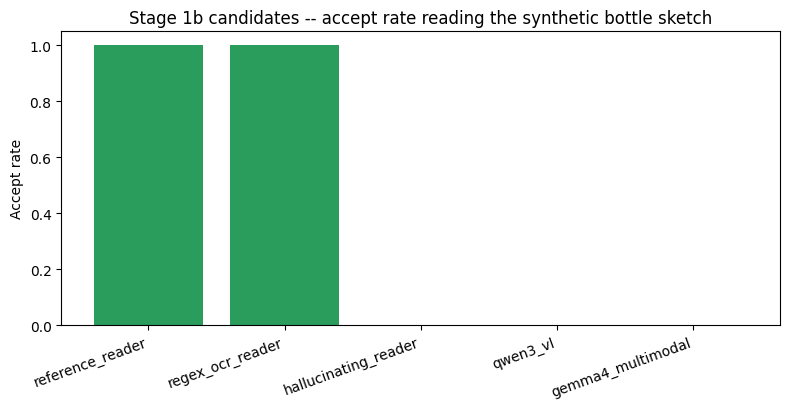

In [11]:
import matplotlib.pyplot as plt

plot_df = summary_df.copy()
# green >= 0.8, amber for partial credit, red for 0% -- NaN (adapter produced
# no trials at all) also renders as red via fillna(0), the right failure color.
colors = ["#2a9d5c" if r >= 0.8 else ("#e0a63a" if r > 0 else "#d64545") for r in plot_df["accept_rate"].fillna(0)]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(plot_df.index, plot_df["accept_rate"].fillna(0), color=colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Accept rate")
ax.set_title("Stage 1b candidates -- accept rate reading the synthetic bottle sketch")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## 7.5 Debug: inspect what a failing model actually output

The summary table above only shows the first failure reason as a one-liner.
This pulls the first failing trial per model (skips models where every trial
passed) and prints the full raw output plus every reason it was rejected --
essential for telling a real hallucination apart from a formatting slip.

In [12]:
for name, trials in all_trials.items():
    failing = [t for t in trials if t["verdict"] != "accept"]
    if not failing:
        continue
    worst = failing[0]
    print(f"===== {name} -- trial {worst['trial']} -- verdict: {worst['verdict']} =====")
    print("reasons:", worst["reasons"])
    print()
    if worst["output"]:
        print(worst["output"])
    else:
        print("(no output -- generation itself failed, see reasons above)")
    print()


===== hallucinating_reader -- trial 0 -- verdict: reject =====
reasons: ["HALLUCINATION: guessed a value for ['ovality_mm', 'shape'] which is not legible in the image or stated in the text -- got [('ovality_mm', 0.3), ('shape', 'round')]", 'unresolved_questions does not flag the ovality/shape gap']

{"machine_id": "CAP-16", "part_family": "starwheel", "target_speed_cpm": 380, "container": {"description": "500 mL PET bottle", "body_diameter_mm": 64.0, "ovality_mm": 0.3, "height_mm": 210, "neck_finish": "PCO-1881", "closure": "28 mm plastic screw", "material": "PET", "filled_weight_g": 520, "shape": "round"}, "unresolved_questions": [], "feasibility_flags": []}

===== qwen3_vl -- trial 0 -- verdict: skipped =====
reasons: ['URLError: <urlopen error Tunnel connection failed: 403 Forbidden>']

(no output -- generation itself failed, see reasons above)

===== gemma4_multimodal -- trial 0 -- verdict: skipped =====
reasons: ['URLError: <urlopen error Tunnel connection failed: 403 Forbidden>']

## 8. Reading these results

- `reference_reader` and `regex_ocr_reader` should both hit **1.0** -- two
  differently-coded but equally correct readings of the same image and text,
  proving Stage 1b model choice should be judged on the *extracted values*,
  not adapter/prompt style.
- `hallucinating_reader` should hit **0.0**, and its
  `hallucinated_ovality_or_shape` column should read `1/1` -- it invents a
  plausible `ovality_mm` and `shape` instead of leaving them null. That's the
  harness working, not a bug: this is exactly the "plausible but wrong"
  failure mode the source doc warns about, now caught before it ever reaches
  a machined part.
- `qwen3_vl` and `gemma4_multimodal` are the two real, currently testable
  candidates. Their accept rate here -- run with your own API key, see
  Section 9 -- is the actual answer to "does this model belong in Stage 1b,"
  not a demo. Read `hallucinated_ovality_or_shape` first: a model that scores
  well on `example_reason_if_any_failed` but still hallucinates ovality/shape
  on even one trial should be treated as failing this stage, because the
  hallucination check is weighted as the critical one, not averaged in as
  just another field.
- In *this* sandbox (no network), `qwen3_vl` and `gemma4_multimodal` show
  `generation_failed`/`skipped` trials with a `RuntimeError`/`URLError`
  reason -- expected here, not a finding about the models themselves.

For a real production decision, don't stop at one image. Loop Section 6 over
a batch of real supplier drawings and photos (once you have some) and
compare accept rate across the batch -- one synthetic sketch, however many
trials, proves the harness works, not that a model is production-ready.

## 9. Running this for real, and what it costs

1. Get an OpenRouter key at openrouter.ai and fund the account (even a $0
   balance triggers HTTP 402 on any model, free tier included, per
   OpenRouter's docs):
   ```bash
   export OPENROUTER_API_KEY=sk-or-...
   ```
2. Re-run this notebook top to bottom (Colab or any machine with outbound
   network access). Sections 1-3 are unchanged; Section 4's two adapters will
   now return real completions instead of `generation_failed`.
3. **Cost: images really do add tokens on top of the text prompt**, which is
   the mechanism behind the source doc's "roughly doubles serving cost." At
   `qwen3-vl-32b-instruct`'s verified $0.104/M input tokens, a single call
   with this notebook's ~250-token text prompt plus a modest sketch image
   (OpenRouter's own image-tokenization guide notes exact image token counts
   vary by provider/resolution, but a few hundred to ~1,000 tokens for a
   simple line drawing at moderate resolution is a reasonable planning
   number) can roughly double the input-token count per call versus the
   text-only Stage 1 prompt -- consistent with the doc's estimate, even
   though OpenRouter doesn't publish one universal per-image multiplier. At
   these verified per-token rates (`qwen3-vl-32b-instruct` $0.104/$0.416 per
   M in/out, `gemma-4-31b-it` $0.08/$0.35 per M in/out), 3 trials each of
   this prompt still costs well under a cent -- the "doubles serving cost"
   effect matters at production volume, not for a benchmark run.
4. To go beyond one synthetic sketch, replace `BOTTLE_IMAGE_PATH` in Section
   1 with a loop over real supplier drawings/photos as you collect them
   (start with whatever scanned PDFs or phone photos already exist in old
   quote emails), regenerate `EXPECTED`/`HALLUCINATION_FIELDS` per real image
   from a human-verified reading of it, and aggregate `accept_rate` across
   the batch -- that's the number that should actually decide which VLM
   serves Stage 1b in production, not this one drawing's result.
5. If a real Stage 1b deployment also needs to read scanned **PDF** drawings
   (not just photos), rasterize each PDF page to PNG first (e.g.
   `pdf2image`/`pymupdf`) and pass that through the same `image_path`
   adapters unchanged -- OpenRouter's chat-completions endpoint takes image
   inputs, not PDF inputs, directly.

## References

- Source doc — Stage 1b section: `model_types_by_stage.md`
- OpenRouter multimodal image-input format: https://openrouter.ai/docs/guides/overview/multimodal/image-understanding
- Qwen3 VL 32B Instruct — model id and pricing: https://openrouter.ai/qwen/qwen3-vl-32b-instruct
- Qwen vendor listing (cross-check for the VL model family): https://openrouter.ai/qwen
- Gemma 4 31B — model id and pricing: https://openrouter.ai/google/gemma-4-31b-it
- Google vendor listing (cross-check for Gemma 4's multimodal support): https://openrouter.ai/google
- OpenRouter vision-models collection: https://openrouter.ai/collections/vision-models